In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import sympy as sp
%matplotlib inline


# I. Метод Эйлера для ОДУ первого порядка.

Рассмотрим уравнение первого порядка
$$\frac{du}{dt} = \lambda u$$
С начальным условием $u(t = 0) = u_0$.

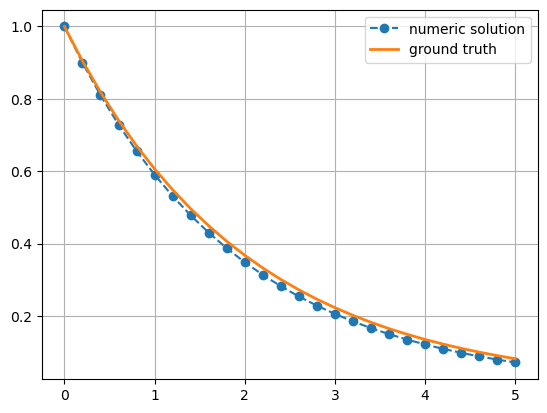

In [3]:
def euler_solve(lam, u0, T, dt):
    num_steps = int(T/dt)
    tt = np.arange(num_steps+1)*dt
    y = np.empty(num_steps+1)
    y[0] = u0
    for k in range(num_steps):
        y[k+1] = y[k] + dt*lam*y[k]
    return tt, y

lam = -0.5
tt, y = euler_solve(lam, u0=1.0, T=5, dt=0.1/abs(lam))
plt.plot(tt, y, 'o--', label='numeric solution')
plt.plot(tt, np.exp(lam*tt), '-', lw=2, label='ground truth')
plt.legend(loc='best')
plt.grid(True)
plt.show()

Теперь попробуем задать значение шага $\tau$ (в коде это dt) такое, что $|\lambda|\tau > 1$.

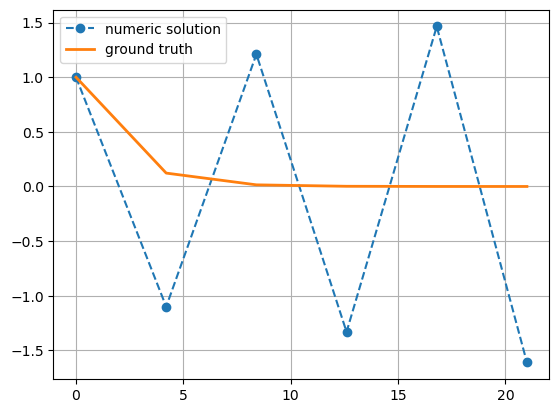

In [4]:
lam = -0.5
tt, y = euler_solve(lam, u0=1.0, T=12/abs(lam), dt=2.1/abs(lam))
plt.plot(tt, y, 'o--', label='numeric solution')
plt.plot(tt, np.exp(lam*tt), '-', lw=2, label='ground truth')
plt.legend(loc='best')
plt.grid(True)
plt.show()

# Задание 1. Неявный метод Эйлера.
Решите то же самое уравнение
$$\frac{du}{dt} = \lambda u,$$
используя неявную схему Эйлера. Сравните поведение неявной и явной схем Эйлера. Постройте решение для нескольких значений шага интегрирования, опишите поведение решения при $\lambda\tau > 2$.

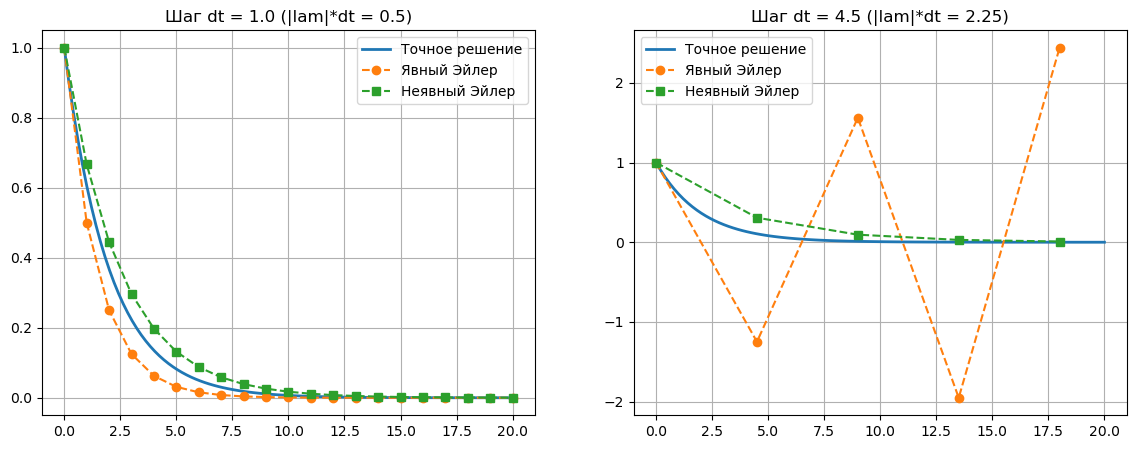

In [5]:
def euler_solve(lam, u0, T, dt):
    # Явный метод
    num_steps = int(T/dt)
    tt = np.arange(num_steps+1)*dt
    y = np.empty(num_steps+1)
    y[0] = u0
    for k in range(num_steps):
        y[k+1] = y[k] + dt*lam*y[k]
    return tt, y

def implicit_euler_solve(lam, u0, T, dt):
    # Неявный метод
    num_steps = int(T/dt)
    tt = np.arange(num_steps+1)*dt
    y = np.empty(num_steps+1)
    y[0] = u0
    for k in range(num_steps):
        y[k+1] = y[k] / (1 - dt * lam)
    return tt, y

# Инициализация
lam = -0.5
u0 = 1.0
T = 20

# Варианты шагов
dts = [1.0, 4.5] 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Отрисовка графиков
for ax, dt in zip(axes, dts):
    tt_ex, y_ex = euler_solve(lam, u0, T, dt)
    tt_im, y_im = implicit_euler_solve(lam, u0, T, dt)
    
    tt_true = np.linspace(0, T, 100)
    y_true = np.exp(lam * tt_true)
    
    ax.plot(tt_true, y_true, '-', lw=2, label='Точное решение')
    ax.plot(tt_ex, y_ex, 'o--', label='Явный Эйлер')
    ax.plot(tt_im, y_im, 's--', label='Неявный Эйлер')
    
    ax.set_title(f'Шаг dt = {dt} (|lam|*dt = {abs(lam)*dt})')
    ax.legend()
    ax.grid(True)

plt.show()


tt_test, y_test = implicit_euler_solve(lam, u0=1.0, T=8/abs(lam), dt=2.1/abs(lam))
assert (y_test > 0).all()

# II. Системы линейных уравнений
Рассмотрим систему двух уравнений первого порядка.
$$\frac{d\mathbf{u}}{dt} = A\mathbf{u}$$
где $\mathbf{u}$ есть вектор длины 2, $A = \text{const}$ - заданная матрица $2 \times 2$.

# Задание 2. Сравнение явной схемы Эйлера и матричной экспоненты.
Выполните обобщение алгоритма `euler_solve` для решения систем линейных уравнений первого порядка с матрицей $A$, не зависящей от времени, используя явную схему Эйлера.

In [6]:
def euler_solve2(a, u0, T, dt):
    r"""Solve the system du/dt = Au via an explicit Euler scheme.

    Parameters
    ----------
    a : ndarray, shape(ndim, ndim)
        The matrix of the l.h.s.
    u0 : ndarray, shape(ndim,)
        Initial condition
    T : float
        construct the solution for $t\in [0, T)$
    dt : float
        Integration step size $\tau$

    Returns
    -------
    t : ndarray, shape (n,)
        Integration times
    y : ndarray, shape (n, ndim)
        Solution of the FD system. 
        y[k, :] is the solution at t[k].
    """
    a = np.asarray(a, dtype=float)
    u0 = np.asarray(u0, dtype=float)
    num_steps = int(T/dt)
    tt = np.arange(num_steps+1)*dt
    ndim = a.shape[0]
    
    y = np.zeros((num_steps + 1, ndim))
    y[0] = u0
    
    for k in range(num_steps):
        y[k+1] = y[k] + dt * (a @ y[k])
        
    return tt, y

Напишите функцию, возвращающую решение задачи Коши для системы уравнений $du/dt = A\mathbf{u}$ с постоянной матрицей $A$ через матричную экспоненту. (Используйте библиотечную функцию `scipy.linalg.expm`)

In [7]:
def mat_exp_solve(a, u0, tt):
    r"""Construct the solution of $du/dt = A u$ with $u(t=0) = u_0$ at times `tt`.

    Parameters
    ----------
    a : ndarray, shape (ndim, ndim)
    u0 : ndarray, shape (ndim,)
    tt : ndarray, shape (n,)
        The values of $t$

    Return
    ------
    u : ndarray, shape (n, ndim)
        u[:, k] is $\exp(t[k] A)$
    """
    a = np.asarray(a, dtype=float)
    u0 = np.asarray(u0, dtype=float)
    
    n = len(tt)
    ndim = len(u0)
    
    u = np.zeros((n, ndim))
    
    for k, t in enumerate(tt):
        u[k, :] = expm(a * t) @ u0
        
    return u

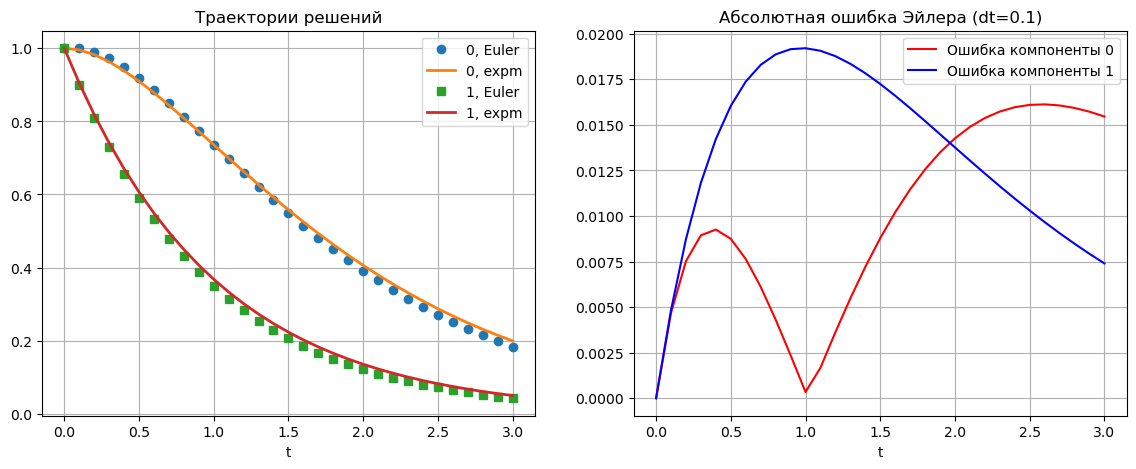

In [8]:
# Сравните здесь метод Эйлера с методом матричной экспоненты
a = np.array([[-1, 1],
              [0, -1]], dtype=float)
u0 = [1.0, 1.0]
T = 3.0
dt = 0.1

# Получение решений
t, y_euler = euler_solve2(a, u0, T, dt)
y_exact = mat_exp_solve(a, u0, t)

# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: сравнение траекторий
ax1.plot(t, y_euler[:, 0], 'o', label='0, Euler')
ax1.plot(t, y_exact[:, 0], '-', lw=2, label='0, expm')
ax1.plot(t, y_euler[:, 1], 's', label='1, Euler')
ax1.plot(t, y_exact[:, 1], '-', lw=2, label='1, expm')
ax1.set_title('Траектории решений')
ax1.set_xlabel('t')
ax1.legend(loc='best')
ax1.grid(True)

# Правый график: абсолютная ошибка
error = np.abs(y_euler - y_exact)
ax2.plot(t, error[:, 0], 'r-', label='Ошибка компоненты 0')
ax2.plot(t, error[:, 1], 'b-', label='Ошибка компоненты 1')
ax2.set_title(f'Абсолютная ошибка Эйлера (dt={dt})')
ax2.set_xlabel('t')
ax2.legend(loc='best')
ax2.grid(True)

plt.show()

# III. Жесткие системы
Рассмотрим линейную систему, $du/dt = Au$, с матрицей правой части
$$A = \begin{bmatrix} -10 & 10 \\ 32 & -499 \end{bmatrix}$$
с начальным условием $u = (1, 0)^T$.

Система называется жесткой, если для всех $(x, \vec{y}(x))$ (на решениях системы) собственные значения матрицы Якоби системы $\mathbf{J}(x)$ (в данном случае она равна $A$) удовлетворяют условиям
$$\frac{\max_j |\text{Re } \lambda_j|}{\min_k |\text{Re } \lambda_k|} \gg 1, \quad \text{Re } \lambda_j < 0, \quad \frac{\max_j |\text{Im } \lambda_j|}{\max_k |\text{Re } \lambda_k|} \ll 1 \quad \forall j, k$$
Число $s = \frac{\max_i |\text{Re } \lambda_i|}{\min_k |\text{Re } \lambda_k|}$ называется числом жесткости системы.

Пример.
Для решения задачи Коши системы ОДУ используется численный метод Рунге-Кутты, заданный таблицей Бутчера:
$$\begin{cases} u' = -800u + 4 \cdot 10^{-2}v + 2 \cdot 10^{-2}w, u(0) = 0, \\ v' = -5v - 3w, v(0) = 4, \\ w' = v - w, w(0) = 6, \end{cases} \quad \begin{array}{c|cc} 1/5 & 1/5 & 0 \\ 4/5 & 3/5 & 1/5 \\ \hline & 1/2 & 1/2 \end{array}$$

Получим для него функцию и условие устойчивости. Вычислим число жёсткости.
$$R(z) = \frac{1 + \frac{3}{5}z + (\frac{1}{2} - \frac{2}{5} + \frac{1}{25})z^2}{1 - \frac{2}{5}z + \frac{1}{25}z^2}$$
Матрица $\mathbf{J}(x)$ постоянна и ее собственные значения $\lambda_1 = -2, \lambda_2 = -4, \lambda_3 = -800$ лежат на действительной оси. Так как $z_i = \lambda_i h$, то и функцию устойчивости достаточно исследовать на действительной оси.
Область устойчивости определяется из условия $|R(z)| \le 1$. Получаем
$$\text{Im } z_i = 0, \text{Re } z_i (1 + \text{Re } z_i/10) \le 0, i = 1, 2, 3$$
Шаг интегрирования, который удовлетворяет всем условиям $h \in (0, 10/800]$.
Число жесткости $s = 800/2 = 400$.


# Задание 3. Проверка жёсткости системы и неявные методы.
Найдите собственные значения матрицы $A$ (используя `np.linalg.eigvals`) и прокомментируйте, является ли система жесткой.

Решите систему, используя фиксированный шаг
$$\tau = 0.01$$
Стабилен ли метод на шаге такого размера?

Собственные значения матрицы A: [  -9.34647667 -499.65352333]
Число жесткости s = 53.46
Система является жесткой(s>>1)


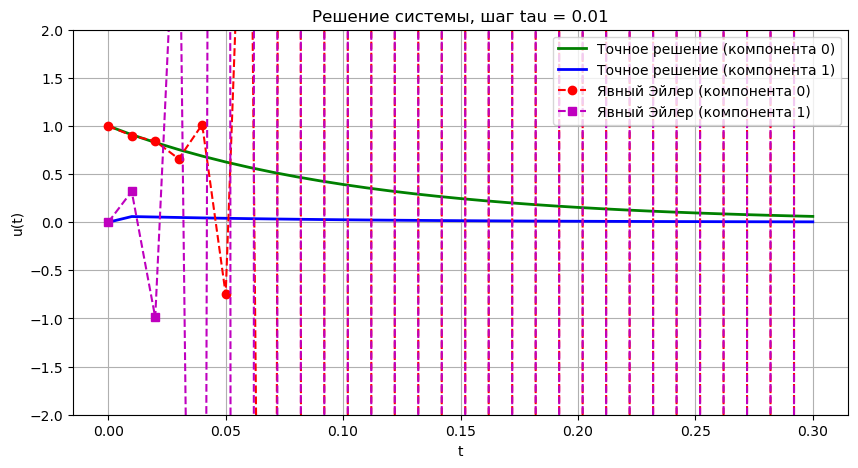

In [9]:
# Задаем матрицу A и начальные условия
A = np.array([[-10, 10],
              [32, -499]], dtype=float)
u0 = np.array([1.0, 0.0])
tau = 0.01
T = 0.3 

# 1. Поиск собственных значений
eigenvalues = np.linalg.eigvals(A)
print(f"Собственные значения матрицы A: {eigenvalues}")

# Расчет числа жесткости
s = np.max(np.abs(np.real(eigenvalues))) / np.min(np.abs(np.real(eigenvalues)))
print(f"Число жесткости s = {s:.2f}")
print("Система является жесткой(s>>1)")

# 2. Решение системы явным методом Эйлера
tt, y_euler = euler_solve2(A, u0, T, tau)
y_exact = mat_exp_solve(A, u0, tt)

# Визуализация
fig, ax = plt.subplots(figsize=(10, 5))

# Строим точное решение
ax.plot(tt, y_exact[:, 0], 'g-', lw=2, label='Точное решение (компонента 0)')
ax.plot(tt, y_exact[:, 1], 'b-', lw=2, label='Точное решение (компонента 1)')

# Строим решение явным методом Эйлера
ax.plot(tt, y_euler[:, 0], 'r--', marker='o', label='Явный Эйлер (компонента 0)')
ax.plot(tt, y_euler[:, 1], 'm--', marker='s', label='Явный Эйлер (компонента 1)')

ax.set_title(f'Решение системы, шаг tau = {tau}')
ax.set_xlabel('t')
ax.set_ylabel('u(t)')
ax.set_ylim(-2, 2) 
ax.legend(loc='best')
ax.grid(True)
plt.show()

Постройте графики решения системы на интервале $0 < t < 1$ с начальным условием $u = (1, 0)^T$ используя функции `euler_solve2` и `mat_exp_solve`. Используйте несколько значений шага, например $\tau = 4 \cdot 10^{-3}$ и $\tau = 4.5 \cdot 10^{-3}$. Прокомментируйте поведение решений.

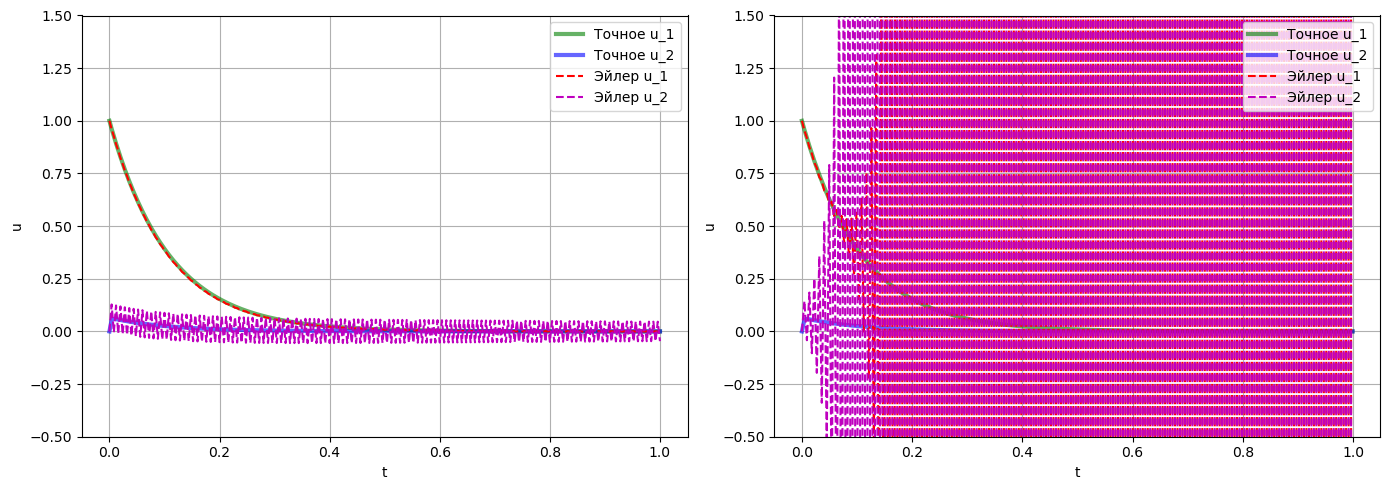

In [10]:
A = np.array([[-10, 10],
              [32, -499]], dtype=float)
u0 = np.array([1.0, 0.0])
T = 1.0
taus = [4e-3, 4.5e-3]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, tau in zip(axes, taus):
    t_euler, y_euler = euler_solve2(A, u0, T, tau)
    
    y_exact = mat_exp_solve(A, u0, t_euler)
    
    ax.plot(t_euler, y_exact[:, 0], '-', color='green', lw=3, label='Точное u_1', alpha=0.6)
    ax.plot(t_euler, y_exact[:, 1], '-', color='blue', lw=3, label='Точное u_2', alpha=0.6)
    
    ax.plot(t_euler, y_euler[:, 0], 'r--', label='Эйлер u_1')
    ax.plot(t_euler, y_euler[:, 1], 'm--', label='Эйлер u_2')
    
    ax.set_xlabel('t')
    ax.set_ylabel('u')
    ax.grid(True)
    ax.legend(loc='upper right')
    
    ax.set_ylim(-0.5, 1.5)

plt.tight_layout()
plt.show()

Для tau = 4.5e-3 - 1-lambda_{max}tau < 1. На каждом шаге "быстрая" компонента ошибки умножается на отрицательное число, большее единицы по модулю. Это приводит к экспоненциально нарастающим колебаниям с чередованием знака.

Реализуйте неявную схему Эйлера для системы линейных уравнений первого порядка с постоянными коэффициентами. Заметьте, что на каждом шаге вам необходимо решать систему линейных алгебраических уравнений (используйте `np.linalg.solve`).

Сравните решения, полученные явной и неявной схемами Эйлера.

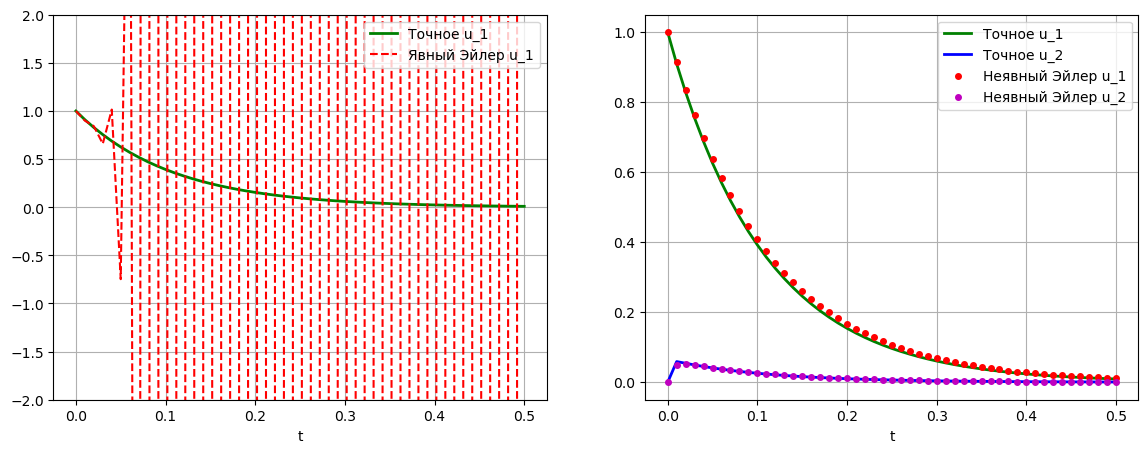

In [12]:
def implicit_euler_solve2(a, u0, T, dt):
    """Решает систему du/dt = Au с помощью неявной схемы Эйлера."""
    a = np.asarray(a, dtype=float)
    u0 = np.asarray(u0, dtype=float)
    num_steps = int(T/dt)
    tt = np.arange(num_steps+1)*dt
    ndim = a.shape[0]
    
    y = np.zeros((num_steps + 1, ndim))
    y[0] = u0
    
    # Левая часть СЛАУ: M = (I - dt * A)
    M = np.eye(ndim) - dt * a
    
    for k in range(num_steps):
        # Решение СЛАУ M * y[k+1] = y[k] на каждом шаге
        y[k+1] = np.linalg.solve(M, y[k])
        
    return tt, y

# --- Сравнение схем ---
A = np.array([[-10, 10],
              [32, -499]], dtype=float)
u0 = np.array([1.0, 0.0])
T = 0.5
tau = 0.01  # Шаг, при котором явный метод нестабилен

# Получение решений
t_ex, y_ex = euler_solve2(A, u0, T, tau)
t_im, y_im = implicit_euler_solve2(A, u0, T, tau)
y_exact = mat_exp_solve(A, u0, t_im)

# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Явный метод
ax1.plot(t_ex, y_exact[:, 0], 'g-', lw=2, label='Точное u_1')
ax1.plot(t_ex, y_ex[:, 0], 'r--', label='Явный Эйлер u_1')
ax1.set_ylim(-2, 2)
ax1.set_xlabel('t')
ax1.grid(True)
ax1.legend()

# График 2: Неявный метод
ax2.plot(t_im, y_exact[:, 0], 'g-', lw=2, label='Точное u_1')
ax2.plot(t_im, y_exact[:, 1], 'b-', lw=2, label='Точное u_2')
ax2.plot(t_im, y_im[:, 0], 'ro', markersize=4, label='Неявный Эйлер u_1')
ax2.plot(t_im, y_im[:, 1], 'mo', markersize=4, label='Неявный Эйлер u_2')
ax2.set_xlabel('t')
ax2.grid(True)
ax2.legend()

plt.show()

# Задание 4*. Исследование на A- и L-устойчивость.
Определить функцию устойчивости и область устойчивости метода Рунге-Кутты заданного таблицей Бутчера:
$$\begin{array}{c|cc} 0 & 0 & 0 \\ 2 & 3/2 & 1/2 \\ \hline & 3/4 & 1/4 \end{array}$$
Исследовать его на A- и L-устойчивость.


**1. Вычисление функции устойчивости $R(z)$**

Из таблицы Бутчера берем матрицу $B = \begin{pmatrix} 0 & 0 \\ 3/2 & 1/2 \end{pmatrix}$ и вектор $\vec{\gamma}^T = \begin{pmatrix} 3/4 & 1/4 \end{pmatrix}$.
Формула функции устойчивости:
$$R(z) = \frac{\det(E - zB + z\vec{1}\vec{\gamma}^T)}{\det(E - zB)}$$

Вычисляем знаменатель:
$$\det(E - zB) = \det\begin{pmatrix} 1 & 0 \\ -3z/2 & 1 - z/2 \end{pmatrix} = 1 - \frac{z}{2}$$

Вычисляем матрицу для числителя и её определитель:
$$E - zB + z\vec{1}\vec{\gamma}^T = \begin{pmatrix} 1 & 0 \\ -3z/2 & 1 - z/2 \end{pmatrix} + \begin{pmatrix} 3z/4 & z/4 \\ 3z/4 & z/4 \end{pmatrix} = \begin{pmatrix} 1 + 3z/4 & z/4 \\ -3z/4 & 1 - z/4 \end{pmatrix}$$
$$\det(\dots) = \left(1 + \frac{3z}{4}\right)\left(1 - \frac{z}{4}\right) - \left(-\frac{3z}{4}\right)\left(\frac{z}{4}\right) = 1 - \frac{z}{4} + \frac{3z}{4} - \frac{3z^2}{16} + \frac{3z^2}{16} = 1 + \frac{z}{2}$$

Итоговая функция устойчивости:
$$R(z) = \frac{1 + z/2}{1 - z/2}$$

**2. Исследование на A-устойчивость**

Область устойчивости определяется неравенством $|R(z)| \le 1$. Пусть $z = x + iy$:
$$ \left| \frac{1 + \frac{x}{2} + i\frac{y}{2}}{1 - \frac{x}{2} - i\frac{y}{2}} \right|^2 \le 1 \implies \left(1 + \frac{x}{2}\right)^2 + \left(\frac{y}{2}\right)^2 \le \left(1 - \frac{x}{2}\right)^2 + \left(\frac{y}{2}\right)^2 $$
$$ 1 + x + \frac{x^2}{4} \le 1 - x + \frac{x^2}{4} \implies 2x \le 0 \implies x \le 0 $$
Область устойчивости — вся левая комплексная полуплоскость ($\text{Re}(z) \le 0$). Следовательно, метод **А-устойчив**.

**3. Исследование на L-устойчивость**

Для L-устойчивости А-устойчивого метода требуется выполнение предела $\lim_{z \to -\infty} |R(z)| = 0$.
Проверяем:
$$ \lim_{z \to -\infty} R(z) = \lim_{z \to -\infty} \frac{1 + z/2}{1 - z/2} = \lim_{z \to -\infty} \frac{2/z + 1}{2/z - 1} = -1 $$
Так как $|-1| = 1 \neq 0$, метод **НЕ является L-устойчивым**.

# Задание 5*. Исследование на жесткость и область устойчивости.
Для решения задачи Коши системы ОДУ используется численный метод Рунге-Кутты, заданный таблицей Бутчера:
$$\begin{cases} u' = -400u, u(0) = 1, \\ v' = 3 \cdot 10^{-2}u - 10v + w, v(0) = -1, \\ w' = -4 \cdot 10^{-2}u - 12v - 2w, w(0) = 0, \end{cases} \quad \begin{array}{c|cc} 1/8 & 1/8 & 0 \\ 7/8 & 3/4 & 1/8 \\ \hline & 1/2 & 1/2 \end{array}$$
Получите для него функцию и условие устойчивости. Вычислите число жёсткости.


**1. Вычисление числа жесткости**

Матрица Якоби $J$ для заданной линейной системы ОДУ имеет вид:
$$ J = \begin{pmatrix} -400 & 0 & 0 \\ 0.03 & -10 & 1 \\ -0.04 & -12 & -2 \end{pmatrix} $$
$$\lambda_1 = -400,\lambda_2 = -4, \lambda_3 = -8. $$
Спектр лежит на действительной отрицательной полуоси. Число жесткости $s$:
$$ s = \frac{\max|\text{Re}(\lambda)|}{\min|\text{Re}(\lambda)|} = \frac{400}{4} = 100 $$
Система является **жесткой**.

**2. Функция устойчивости $R(z)$**

Из таблицы Бутчера: $B = \begin{pmatrix} 1/8 & 0 \\ 3/4 & 1/8 \end{pmatrix}, \quad \vec{\gamma}^T = \begin{pmatrix} 1/2 & 1/2 \end{pmatrix}$. 
Формула: $R(z) = \frac{\det(E - zB + z\vec{1}\vec{\gamma}^T)}{\det(E - zB)}$.

Вычисляем знаменатель:
$$ \det(E - zB) = \det\begin{pmatrix} 1 - z/8 & 0 \\ -3z/4 & 1 - z/8 \end{pmatrix} = \left(1 - \frac{z}{8}\right)^2 = 1 - \frac{z}{4} + \frac{z^2}{64} $$

Вычисляем числитель:
$$ E - zB + z\vec{1}\vec{\gamma}^T = \begin{pmatrix} 1 - z/8 & 0 \\ -3z/4 & 1 - z/8 \end{pmatrix} + \begin{pmatrix} z/2 & z/2 \\ z/2 & z/2 \end{pmatrix} = \begin{pmatrix} 1 + 3z/8 & z/2 \\ -z/4 & 1 + 3z/8 \end{pmatrix} $$
$$ \det(\dots) = \left(1 + \frac{3z}{8}\right)^2 - \left(\frac{z}{2}\right)\left(-\frac{z}{4}\right) = 1 + \frac{3z}{4} + \frac{9z^2}{64} + \frac{8z^2}{64} = 1 + \frac{3z}{4} + \frac{17z^2}{64} $$

Итоговая функция устойчивости:
$$ R(z) = \frac{1 + 3z/4 + 17z^2/64}{1 - z/4 + z^2/64} $$

**3. Условие устойчивости**

Поскольку собственные значения системы действительны, $z = \lambda h \in \mathbb{R}$. Знаменатель $\left(1 - z/8\right)^2 > 0$ при $z \le 0$. 
Исследуем условие $|R(z)| \le 1$ на действительной оси:

Правая граница $R(z) \le 1$:
$$ 1 + \frac{3z}{4} + \frac{17z^2}{64} \le 1 - \frac{z}{4} + \frac{z^2}{64} \implies z + \frac{16z^2}{64} \le 0 \implies z\left(1 + \frac{z}{4}\right) \le 0 $$
Так как $z \le 0$ (из $\lambda < 0, h > 0$), неравенство выполняется при $1 + z/4 \ge 0 \implies z \ge -4$.

Левая граница $R(z) \ge -1$:
$$ 1 + \frac{3z}{4} + \frac{17z^2}{64} \ge -1 + \frac{z}{4} - \frac{z^2}{64} \implies 2 + \frac{z}{2} + \frac{18z^2}{64} \ge 0 $$
Для $z \in [-4, 0]$ слагаемое $(2 + z/2) \ge 0$, а квадрат всегда неотрицателен, поэтому левое неравенство выполняется всегда в этой зоне.


Рассмотрим ОДУ второго порядка, описывающее осцилляции маятника
$$\frac{d^2u}{dt^2} + \omega^2 u = 0$$


# Задание 6. Законы сохранения и решение ОДУ.
Преобразуйте данное уравнение второго порядка в систему ОДУ первого порядка.
Решите данную систему уравнений, используя явную схему Эйлера на интервале времени не менее десяти периодов осцилляций.

Мы знаем, что в отсутствии трения выполняется закон сохранения энергии:
$$E = \frac{(du/dt)^2}{2} + \frac{\omega^2 u^2}{2}$$
Постройте зависимость $E$ от времени для вашего численного решения. Используйте несколько значений шага. Выполняется ли закон сохранения энергии?

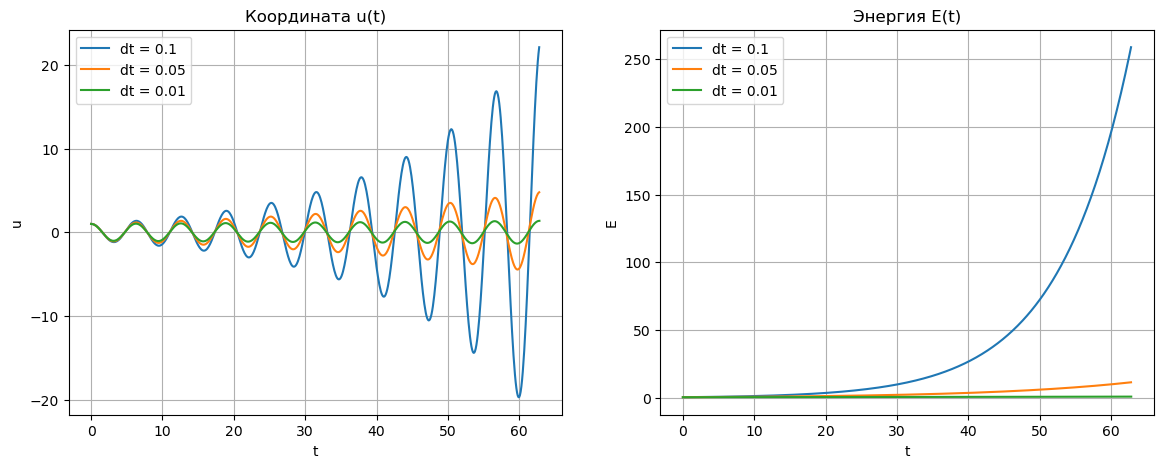

In [2]:
# Параметры системы
w = 1.0  # omega
u0 = 1.0 # начальная координата
v0 = 0.0 # начальная скорость

# Время моделирования (не менее 10 периодов)
T_period = 2 * np.pi / w
T_total = 10 * T_period

# Разные значения шага
dts = [0.1, 0.05, 0.01]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for dt in dts:
    num_steps = int(T_total / dt)
    t = np.arange(num_steps + 1) * dt
    
    u = np.zeros(num_steps + 1)
    v = np.zeros(num_steps + 1)
    u[0], v[0] = u0, v0
    
    # Явный метод Эйлера
    for k in range(num_steps):
        u[k+1] = u[k] + dt * v[k]
        v[k+1] = v[k] - dt * (w**2) * u[k]
        
    # Вычисление энергии
    E = 0.5 * v**2 + 0.5 * (w**2) * u**2
    
    # Отрисовка
    ax1.plot(t, u, label=f'dt = {dt}')
    ax2.plot(t, E, label=f'dt = {dt}')

ax1.set_title('Координата u(t)')
ax1.set_xlabel('t')
ax1.set_ylabel('u')
ax1.legend()
ax1.grid(True)

ax2.set_title('Энергия E(t)')
ax2.set_xlabel('t')
ax2.set_ylabel('E')
ax2.legend()
ax2.grid(True)

plt.show()

Реализуйте схему Рунге-Кутта второго порядка. Используте ее для решения того же уравнения с теми же значениями шага $\tau$. Сравните решения, полученные методом Рунге-Кутта и методом Эйлера на одинаковых промежутках времени. Проверьте закон сохранения энергии. Обсудите.

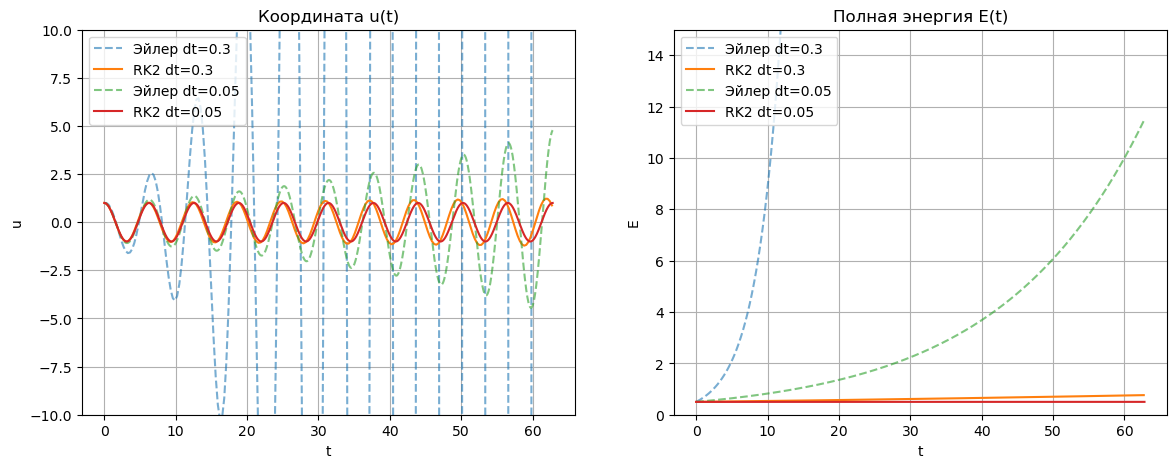

In [8]:
# Параметры системы
w = 1.0
u0 = 1.0
v0 = 0.0
T_period = 2 * np.pi / w
T_total = 10 * T_period

dts = [0.3, 0.05]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for dt in dts:
    num_steps = int(T_total / dt)
    t = np.arange(num_steps + 1) * dt
    
    # Массивы для метода Эйлера
    u_eu = np.zeros(num_steps + 1)
    v_eu = np.zeros(num_steps + 1)
    u_eu[0], v_eu[0] = u0, v0
    
    # Массивы для метода Рунге-Кутты 2-го порядка (метод Хойна)
    u_rk = np.zeros(num_steps + 1)
    v_rk = np.zeros(num_steps + 1)
    u_rk[0], v_rk[0] = u0, v0
    
    for k in range(num_steps):
        # 1. Явный метод Эйлера
        u_eu[k+1] = u_eu[k] + dt * v_eu[k]
        v_eu[k+1] = v_eu[k] - dt * (w**2) * u_eu[k]
        
        # 2. Метод Рунге-Кутты 2-го порядка
        # Предиктор (промежуточный шаг Эйлера)
        k1_u = v_rk[k]
        k1_v = -(w**2) * u_rk[k]
        
        u_temp = u_rk[k] + dt * k1_u
        v_temp = v_rk[k] + dt * k1_v
        
        # Корректор
        k2_u = v_temp
        k2_v = -(w**2) * u_temp
        
        u_rk[k+1] = u_rk[k] + 0.5 * dt * (k1_u + k2_u)
        v_rk[k+1] = v_rk[k] + 0.5 * dt * (k1_v + k2_v)
        
    # Вычисление энергий
    E_eu = 0.5 * v_eu**2 + 0.5 * (w**2) * u_eu**2
    E_rk = 0.5 * v_rk**2 + 0.5 * (w**2) * u_rk**2
    
    # Отрисовка графиков
    ax1.plot(t, u_eu, '--', alpha=0.6, label=f'Эйлер dt={dt}')
    ax1.plot(t, u_rk, '-', label=f'RK2 dt={dt}')
    
    ax2.plot(t, E_eu, '--', alpha=0.6, label=f'Эйлер dt={dt}')
    ax2.plot(t, E_rk, '-', label=f'RK2 dt={dt}')

ax1.set_title('Координата u(t)')
ax1.set_xlabel('t')
ax1.set_ylabel('u')
ax1.legend(loc='upper left')
ax1.set_ylim(-10, 10)
ax1.grid(True)

ax2.set_title('Полная энергия E(t)')
ax2.set_xlabel('t')
ax2.set_ylabel('E')
ax2.legend(loc='upper left')
ax2.set_ylim(0, 15)
ax2.grid(True)

plt.show()

Решите задачу используя предиктор и корректор. Предиктор - дифференциальное уравнение первого порядка, корректор - закон сохранения энергии. Убедитесь, что при большом количестве шагов закон сохранения энергии теперь сохраняется. Отличается ли полученное решение от точного решения после большого количества шагов?

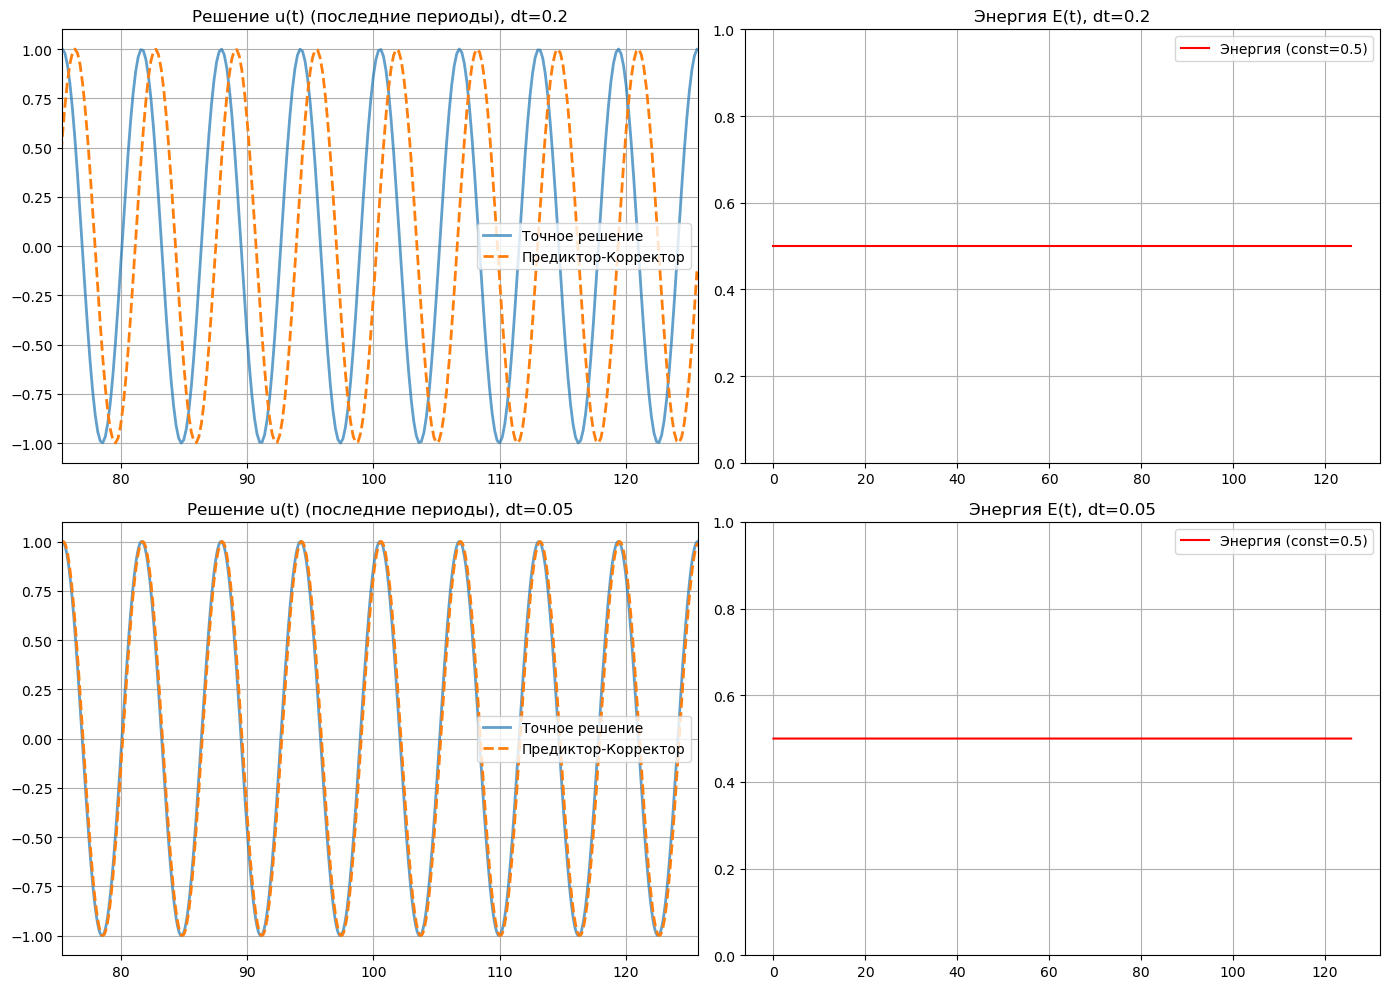

In [11]:
# Параметры системы
w = 1.0
u0 = 1.0
v0 = 0.0
E0 = 0.5 * v0**2 + 0.5 * (w**2) * u0**2 

T_period = 2 * np.pi / w
T_total = 20 * T_period
dts = [0.2, 0.05]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, dt in enumerate(dts):
    num_steps = int(T_total / dt)
    t = np.arange(num_steps + 1) * dt
    
    u = np.zeros(num_steps + 1)
    v = np.zeros(num_steps + 1)
    E = np.zeros(num_steps + 1)
    
    u[0], v[0] = u0, v0
    E[0] = E0
    
    for k in range(num_steps):
        # 1. Предиктор (Метод Эйлера)
        u_p = u[k] + dt * v[k]
        v_p = v[k] - dt * (w**2) * u[k]
        
        # 2. Корректор (по закону сохранения энергии)
        # Вычисляем энергию после шага предиктора
        E_p = 0.5 * v_p**2 + 0.5 * (w**2) * u_p**2
        
        # Находим поправочный коэффициент, чтобы вернуть энергию к E0
        alpha = np.sqrt(E0 / E_p)
        
        # Корректируем значения (проецируем на эллипс постоянной энергии)
        u[k+1] = u_p * alpha
        v[k+1] = v_p * alpha
        
        # Записываем исправленную энергию
        E[k+1] = 0.5 * v[k+1]**2 + 0.5 * (w**2) * u[k+1]**2
        
    u_exact = np.cos(w * t)
    
    # Левые графики: сравнение точного и численного решения на последних периодах
    axes[i, 0].plot(t, u_exact, label='Точное решение', alpha=0.7, lw=2)
    axes[i, 0].plot(t, u, '--', label='Предиктор-Корректор', lw=2)
    axes[i, 0].set_title(f'Решение u(t) (последние периоды), dt={dt}')
    axes[i, 0].set_xlim(T_total - 8*T_period, T_total)
    axes[i, 0].legend()
    axes[i, 0].grid(True)
    
    # Правые графики: полная энергия системы
    axes[i, 1].plot(t, E, color='red', label=f'Энергия (const={E0})')
    axes[i, 1].set_title(f'Энергия E(t), dt={dt}')
    axes[i, 1].set_ylim(0, 1)
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()


# Задание 7. Методы предиктора и корректора для ОДУ.
Используте для решения того же уравнения библиотечную функцию `scipy.integrate.solve_ivp`. Сравните результаты с решениями, полученными методами Рунге-Кутта и Эйлера. Проверьте закон сохранения энергии. Обсудите.

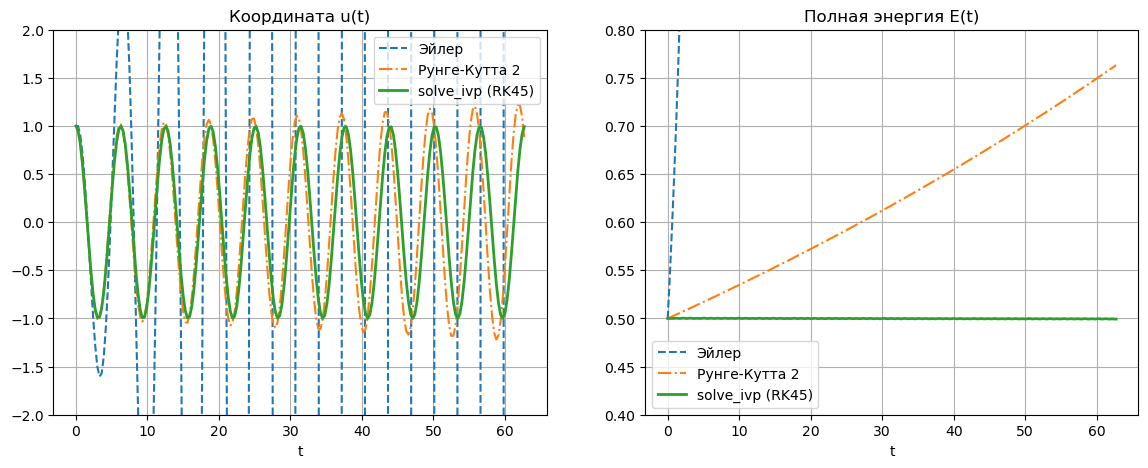

In [15]:
w = 1.0
u0, v0 = 1.0, 0.0
dt = 0.3
T_total = 10 * 2 * np.pi / w
num_steps = int(T_total / dt)
t = np.arange(num_steps + 1) * dt

u_eu = np.zeros(num_steps + 1)
v_eu = np.zeros(num_steps + 1)
u_eu[0], v_eu[0] = u0, v0

u_rk2 = np.zeros(num_steps + 1)
v_rk2 = np.zeros(num_steps + 1)
u_rk2[0], v_rk2[0] = u0, v0

for k in range(num_steps):
    u_eu[k+1] = u_eu[k] + dt * v_eu[k]
    v_eu[k+1] = v_eu[k] - dt * (w**2) * u_eu[k]
    
    k1_u = v_rk2[k]
    k1_v = -(w**2) * u_rk2[k]
    u_tmp = u_rk2[k] + dt * k1_u
    v_tmp = v_rk2[k] + dt * k1_v
    k2_u = v_tmp
    k2_v = -(w**2) * u_tmp
    
    u_rk2[k+1] = u_rk2[k] + 0.5 * dt * (k1_u + k2_u)
    v_rk2[k+1] = v_rk2[k] + 0.5 * dt * (k1_v + k2_v)

def system(t, y):
    return [y[1], -(w**2) * y[0]]

sol = solve_ivp(system, [0, t[-1]], [u0, v0], t_eval=t)
u_ivp = sol.y[0]
v_ivp = sol.y[1]

E_eu = 0.5 * v_eu**2 + 0.5 * (w**2) * u_eu**2
E_rk2 = 0.5 * v_rk2**2 + 0.5 * (w**2) * u_rk2**2
E_ivp = 0.5 * v_ivp**2 + 0.5 * (w**2) * u_ivp**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(t, u_eu, '--', label='Эйлер')
ax1.plot(t, u_rk2, '-.', label='Рунге-Кутта 2')
ax1.plot(t, u_ivp, '-', lw=2, label='solve_ivp (RK45)')
ax1.set_title('Координата u(t)')
ax1.set_xlabel('t')
ax1.set_ylim(-2, 2) 
ax1.legend()
ax1.grid(True)

ax2.plot(t, E_eu, '--', label='Эйлер')
ax2.plot(t, E_rk2, '-.', label='Рунге-Кутта 2')
ax2.plot(t, E_ivp, '-', lw=2, label='solve_ivp (RK45)')
ax2.set_title('Полная энергия E(t)')
ax2.set_xlabel('t')
ax2.set_ylim(0.4, 0.8)
ax2.legend()
ax2.grid(True)

plt.show()

Используя библиотечные функции, реализуйте метод прогноза-коррекции Адамса и метод Милна. Проверьте закон сохранения энергии для каждого из них.

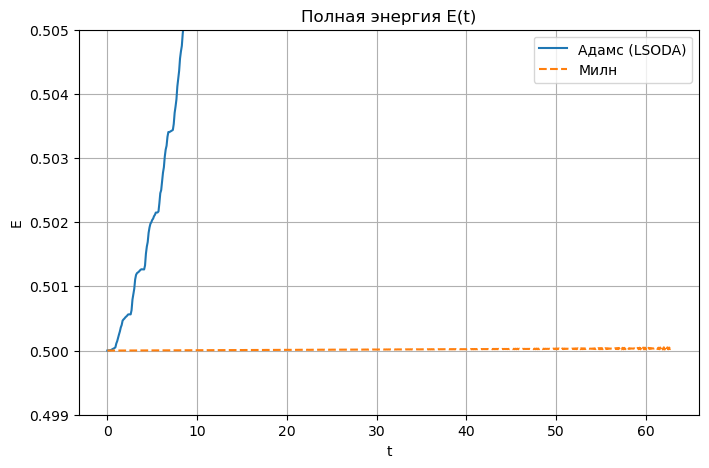

In [24]:
w = 1.0
u0, v0 = 1.0, 0.0
dt = 0.1
T_total = 10 * 2 * np.pi / w

num_steps = int(T_total / dt)
t_eval = np.arange(num_steps + 1) * dt

def system(t, y):
    return [y[1], -(w**2) * y[0]]

# Метод прогноза-коррекции Адамса (Адамс-Башфорт-Мултон)
sol_adams = solve_ivp(system, [t_eval[0], t_eval[-1]], [u0, v0], method='LSODA', t_eval=t_eval)

def milne_step(f, t, y, dt):
    y_pred = y[-4] + 4 * dt / 3 * (2*f(t[-3], y[-3]) - f(t[-2], y[-2]) + 2*f(t[-1], y[-1]))
    
    y_corr = y[-2] + dt / 3 * (f(t[-2], y[-2]) + 4*f(t[-1], y[-1]) + f(t[-1] + dt, y_pred))
    return y_corr

y_milne = np.zeros((num_steps + 1, 2))
t_milne = t_eval.copy()

# Первые 4 точки для Милна берем из метода Рунге-Кутты (solve_ivp RK45)
sol_init = solve_ivp(system, [t_eval[0], t_eval[3]], [u0, v0], method='RK45', t_eval=t_eval[:4])
y_milne[:4] = sol_init.y.T

for i in range(3, num_steps):
    t_hist = t_milne[i-3:i+1]
    y_hist = y_milne[i-3:i+1]
    
    y_next = milne_step(lambda t, y: np.array(system(t, y)), t_hist, y_hist, dt)
    y_milne[i+1] = y_next

# Вычисление энергий
E_adams = 0.5 * sol_adams.y[1]**2 + 0.5 * (w**2) * sol_adams.y[0]**2
E_milne = 0.5 * y_milne[:, 1]**2 + 0.5 * (w**2) * y_milne[:, 0]**2

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_eval, E_adams, label='Адамс (LSODA)')
ax.plot(t_milne, E_milne, '--', label='Милн')
ax.set_title('Полная энергия E(t)')
ax.set_xlabel('t')
ax.set_ylabel('E')
ax.set_ylim(0.499, 0.505)
ax.legend()
ax.grid(True)
plt.show()

# Задание 8. Нелинейное уравнение Пуассона.
Напишите программу, которая решает нелинейное уравнение Пуассона:
$$\phi''(x) = e^{\phi(x)} - n(x), \quad \text{где } n(x) = 1 + e^{-3(x-5)^2}$$
в области $0 \le x \le 10$ с начальными условиями $\phi(0) = 0, \phi'(0) = 0$.
Постройте аналитическое решение с помощью ряда Тейлора и сравните с численным.


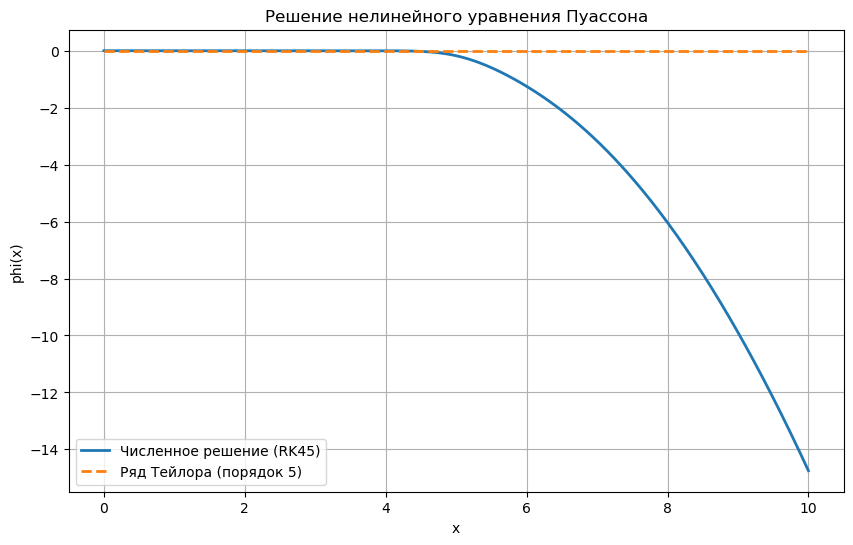

Eq(\phi(x)_{taylor}, -5.9131e-31*x**5 - 9.9891e-32*x**4 - 1.3393e-32*x**3 - 1.3393e-33*x**2)

In [27]:
# 1. Инициализация параметров и функций
def n_func(x):
    return 1 + np.exp(-3 * (x - 5)**2)

def system(x, y):
    phi, dphi = y
    d2phi = np.exp(phi) - n_func(x)
    return [dphi, d2phi]

# 2. Численное решение задачи Коши
x_span = (0, 10)
y0 = [0, 0]
x_eval = np.linspace(x_span[0], x_span[1], 500)

sol = solve_ivp(system, x_span, y0, t_eval=x_eval, method='RK45')

# 3. Символьное вычисление ряда Тейлора
x_sym = sp.Symbol('x')
phi_sym = sp.Function('phi')(x_sym)

k_order = 5
init_conds = {
    phi_sym.subs(x_sym, 0): 0, 
    phi_sym.diff(x_sym).subs(x_sym, 0): 0
}

DE = phi_sym.diff(x_sym, 2) - sp.exp(phi_sym) + 1 + sp.exp(-3*(x_sym-5)**2)

# 4. Итеративный поиск производных в нуле
for i in range(2, k_order + 1):
    DE_diff = DE.diff(x_sym, i - 2).subs(x_sym, 0)
    deriv = phi_sym.diff(x_sym, i).subs(x_sym, 0)
    sol_deriv = sp.solve(DE_diff.subs(init_conds), deriv)[0]
    init_conds[deriv] = sol_deriv

# 5. Сборка многочлена Тейлора
taylor_poly = 0
for i in range(k_order + 1):
    deriv_val = init_conds.get(phi_sym.diff(x_sym, i).subs(x_sym, 0), 0)
    taylor_poly += (deriv_val / sp.factorial(i)) * (x_sym**i)

taylor_func = sp.lambdify(x_sym, taylor_poly, 'numpy')

# 6. Построение графиков
plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol.y[0], label='Численное решение (RK45)', linewidth=2)
plt.plot(sol.t, taylor_func(sol.t), '--', label=f'Ряд Тейлора (порядок {k_order})', linewidth=2)

plt.title('Решение нелинейного уравнения Пуассона')
plt.xlabel('x')
plt.ylabel('phi(x)')
plt.grid(True)
plt.legend()
plt.show()

# 7. Вывод аналитического выражения ряда
display(sp.Eq(sp.Symbol(r'\phi(x)_{taylor}'), taylor_poly.evalf(5)))


# Задание 9. Построение интерфейса и фазовые портреты.
Откройте файл Физическое моделирование.ipynb. В самом низу есть пример и ссылка на много других подобных примеров.
Замените в предыдущей задачи числа и начальные условия на параметры. Постройте интерфейс для её решений и анимируйте фазовый портрет.
Попробуйте, меняя значение производной в нуле, получить решения, при которых $\phi(10) = 0$.



# Задание 10. Построение интерфейса и фазовые портреты-2.
Постройте пользовательский интерфейс для решения дифференциального уравнения
$$\frac{d^2y}{dt^2} = -\omega^2 y(t) - \beta y^3(t)$$
с начальными условиями: $y(0) = q, \frac{dy(0)}{dt} = r$.

Вынесите в пользовательский интерфейс $\omega, \beta, q, r$, число шагов интегрирования, максимальное время интегрирования. Предусмотрите, чтобы можно было бы вводить как положительные, так и отрицательные значения $\beta$. Пользовательский интерфейс должен быть сверстан в два столбца.

Приложение должно отображать $y(t), dy(t)/dt$ и зависимость $dy/dt$ от $y$ (фазовый портрет). Подумайте, как сохранять результаты вычислительных экспериментов для дальнейшего анализа. Анимируйте фазовый портрет.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from scipy.integrate import solve_ivp
import pandas as pd
import time
#%matplotlib notebook
%matplotlib widget

Output()

Output()

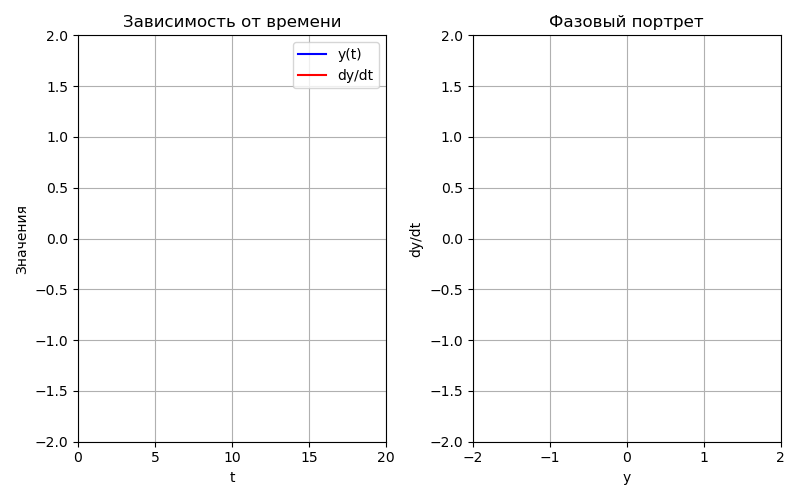

In [ ]:
# 1. Функция системы ОДУ
def oscillator_system(t, state, omega, beta):
    y, dy = state
    return [dy, -omega**2 * y - beta * y**3]

# 2. Глобальный словарь для хранения результатов (для сохранения в файл)
simulation_data = {}

# 3. Элементы интерфейса (виджеты)
w_input = widgets.FloatText(value=1.0, description=r'$\omega$:')
beta_input = widgets.FloatText(value=0.1, description=r'$\beta$:') # Поддерживает отрицательные
q_input = widgets.FloatText(value=1.0, description=r'$q$ ($y_0$):')
r_input = widgets.FloatText(value=0.0, description=r'$r$ ($y''_0$):')
tmax_input = widgets.FloatText(value=20.0, description='T max:')
steps_input = widgets.IntText(value=500, description='Шаги:')

run_button = widgets.Button(description="Решить", button_style='success')
save_button = widgets.Button(description="Сохранить в CSV", button_style='info')
output_log = widgets.Output()

# 4. Верстка в два столбца
col1 = widgets.VBox([w_input, q_input, tmax_input])
col2 = widgets.VBox([beta_input, r_input, steps_input])
ui = widgets.HBox([col1, col2])
buttons = widgets.HBox([run_button, save_button])

# 5. Настройка графиков
out_plot = widgets.Output()

with out_plot:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 5))
    
    # Графики от времени
    line_y, = ax1.plot([], [], 'b-', label='y(t)')
    line_dy, = ax1.plot([], [], 'r-', label='dy/dt')
    ax1.set_xlim(0, 20)
    ax1.set_ylim(-2, 2)
    ax1.set_xlabel('t')
    ax1.set_ylabel('Значения')
    ax1.set_title('Зависимость от времени')
    ax1.legend()
    ax1.grid(True)
    
    # Фазовый портрет
    line_phase, = ax2.plot([], [], 'g-', lw=1.5)
    point_phase, = ax2.plot([], [], 'ko', markersize=5) # Текущая точка
    ax2.set_xlim(-2, 2)
    ax2.set_ylim(-2, 2)
    ax2.set_xlabel('y')
    ax2.set_ylabel('dy/dt')
    ax2.set_title('Фазовый портрет')
    ax2.grid(True)
    
    plt.tight_layout()

# 6. Логика расчетов и анимации
def on_run_clicked(b):
    run_button.disabled = True 
    
    try:
        with output_log:
            clear_output()
            print("Идет расчет...")
            
        omega = w_input.value
        beta = beta_input.value
        q = q_input.value
        r = r_input.value
        t_max = tmax_input.value
        steps = steps_input.value
        
        # Решение ОДУ
        t_eval = np.linspace(0, t_max, steps)
        sol = solve_ivp(oscillator_system, [0, t_max], [q, r], args=(omega, beta), t_eval=t_eval, method='RK45')
        
        t = sol.t
        y = sol.y[0]
        dy = sol.y[1]
        
        # ФАКТИЧЕСКОЕ количество шагов (решатель мог остановиться раньше!)
        actual_steps = len(t)
        
        if not sol.success:
            with output_log:
                print(f"ВНИМАНИЕ: {sol.message}")
                print(f"Решатель остановился на t={t[-1]:.2f}. Система ушла в бесконечность!")
        
        # Сохраняем данные
        simulation_data['t'] = t
        simulation_data['y'] = y
        simulation_data['dy'] = dy
        
        # Обновление пределов графиков
        ax1.set_xlim(0, max(t[-1], 0.1)) # Используем t[-1], а не t_max
        ax1.set_ylim(min(min(y), min(dy)) * 1.1, max(max(y), max(dy)) * 1.1)
        
        ax2.set_xlim(min(y) * 1.1, max(y) * 1.1)
        ax2.set_ylim(min(dy) * 1.1, max(dy) * 1.1)
        
        # Анимация
        frames = min(actual_steps, 200) 
        step_size = max(1, actual_steps // frames) # max(1, ...) защищает от шага 0
        
        with output_log:
            if sol.success:
                clear_output()
            print("Анимация...")
            
        # Цикл до actual_steps, а не до steps!
        for i in range(1, actual_steps, step_size):
            line_y.set_data(t[:i], y[:i])
            line_dy.set_data(t[:i], dy[:i])
            
            line_phase.set_data(y[:i], dy[:i])
            point_phase.set_data([y[i-1]], [dy[i-1]])
            
            fig.canvas.draw()
            time.sleep(0.01)
            
        # Отрисовка финального кадра (чтобы хвост точно дошел до конца)
        line_y.set_data(t, y)
        line_dy.set_data(t, dy)
        line_phase.set_data(y, dy)
        point_phase.set_data([y[-1]], [dy[-1]])
        fig.canvas.draw()
        
        with output_log:
            print("Готово!")
            
    finally:
        run_button.disabled = False

# 7. Логика сохранения данных
def on_save_clicked(b):
    with output_log:
        if 't' in simulation_data:
            df = pd.DataFrame(simulation_data)
            filename = f"phase_data_w{w_input.value}_b{beta_input.value}.csv"
            df.to_csv(filename, index=False)
            print(f"Данные успешно сохранены в файл: {filename}")
        else:
            print("Сначала запустите расчет!")

run_button.on_click(on_run_clicked)
save_button.on_click(on_save_clicked)

# Отображение интерфейса
display(ui, buttons, output_log, out_plot)